# 01 · Single phase: physics of one synchronous buck phase

1. a switched model of one phase with the states of eq. (9.2), integrated **by events** (exact between edges) → `vrm4hil_model.single_phase`;
2. verification of eq. (9.3) and (9.4) on the model, with relative errors → §2–§3;
3. $v_{sw}$ and $i_L$ over two periods in three cases: high average current, valley near zero, negative average current → §4;
4. the characteristic "commanded duty → average voltage" at constant current, for both current signs, with dead times of 5, 20 and 40 ns → §5.

**Conventions.** Single phase driving the whole output network ($C$ = 6 mF, $R_{ESR}$ = 0.3 mΩ) with an impressed load current $i_{load}$ = constant.
At steady state the inductor therefore carries $\langle i_L\rangle = i_{load}$. The commanded duty $D$ is the on-time of the high-side, $D\,T_{sw}$;
both dead times are taken from the low-side ($t_{df}$ after H turns off, $t_{dr}$ before H turns on).
Steady states are found by brute force (`steady_state`): periods are simulated one after the other until the state stops changing. A full run takes several minutes.

In [1]:
import sys
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

sys.path.insert(0, "..")
from vrm4hil_model.params import load_params, phase_params
from vrm4hil_model.single_phase import SinglePhaseEventDriven

P = load_params()
pp = phase_params(P, 1, "M0")                     # nominal phase, dead times 20 ns
pp_no_dt = replace(pp, t_dr_s=0.0, t_df_s=0.0)    # what eq. 9.3 and 9.4 describe
model = SinglePhaseEventDriven(pp)
model_no_dt = SinglePhaseEventDriven(pp_no_dt)

V_OUT_V = P["power_stage"]["VID"]["nominal"]      # 0.80 V
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#e8743b", "#19a979", "#8a8a85"
pp

PhaseParams(v_in_v=12.0, l_h=1.5e-07, dcr_ohm=0.0002, r_on_h_ohm=0.003, r_on_l_ohm=0.001, v_f_v=0.7, r_d_ohm=0.002, c_f=0.006, esr_ohm=0.0003, f_sw_hz=500000.0, t_dr_s=2e-08, t_df_s=2e-08, pulse_extension_s=0.0)

In [2]:
def r_ph(pp, D):
    """Equivalent phase resistance, eq. 9.3."""
    return pp.dcr_ohm + D * pp.r_on_h_ohm + (1 - D) * pp.r_on_l_ohm


def duty_eq_9_3(pp, i_a, v_out_v):
    """Eq. 9.3 solved exactly for D (R_ph itself depends on D)."""
    return (v_out_v + (pp.dcr_ohm + pp.r_on_l_ohm) * i_a) / (pp.v_in_v - (pp.r_on_h_ohm - pp.r_on_l_ohm) * i_a)


def vout_eq_9_3(pp, i_a, D):
    """Eq. 9.3 solved for V_out."""
    return D * pp.v_in_v - r_ph(pp, D) * i_a


def ripple_eq_9_4(pp, D, v_out_v):
    """Eq. 9.4, rising-slope form."""
    return (pp.v_in_v - v_out_v) * D / (pp.l_h * pp.f_sw_hz)


def period_avg(t_s, y):
    return np.trapezoid(y, t_s) / (t_s[-1] - t_s[0])


def steady(model, D, i_load_a, h_s=5e-9, periods=1):
    """Waveforms over `periods` periods at steady state, sampled every h_s (states are exact)."""
    x = model.steady_state(D, i_load_a, [[i_load_a], [D * model.p.v_in_v]])
    t_all, x_all, st_all = [0.0], [x], ["HIGH_SIDE"]
    for k in range(periods):
        t_s, xs, st = model.simulate_period(x, D, i_load_a, h_s=h_s)
        t_all += [k * model.p.t_sw_s + t for t in t_s[1:]]
        x_all += xs[1:]
        st_all += st[1:]
        x = xs[-1]
    X = np.hstack(x_all)
    v_sw = np.array([model.node_voltage(X[:, n], s, i_load_a) for n, s in enumerate(st_all)])
    return dict(t=np.array(t_all), i_l=X[0], v_o=model.output_voltage(X, i_load_a), v_sw=v_sw)


def avg_vout(model, D, i_load_a):
    w = steady(model, D, i_load_a)
    return period_avg(w["t"], w["v_o"])

## 1 · Operating point: what `duty_eq_9_3` means

At steady state the inductor current repeats every period, so the average of $L\,di_L/dt$ over a period is zero. Averaging eq. (9.1):

$$\langle v_{sw}\rangle = \mathrm{DCR}\,I + V_o .$$

Without dead time the node is at $V_{in} - R_{on,H} I$ for $D\,T_{sw}$ and at $-R_{on,L} I$ for the rest, so
$\langle v_{sw}\rangle = D V_{in} - \big(D R_{on,H} + (1-D) R_{on,L}\big) I$ and

$$D\,V_{in} = V_o + R_{ph}(D)\,I, \qquad R_{ph}(D) = \mathrm{DCR} + D R_{on,H} + (1-D) R_{on,L}. \tag{9.3}$$

Two different ratios appear, and it is easy to mix them up:

* the **commanded duty** $D$: what the DPWM actually produces, the on-time of the high-side;
* the **conversion ratio** $M = V_o / V_{in}$: the duty an *ideal* (lossless) buck would need.

With $I > 0$ the resistive drop $R_{ph} I$ eats part of the node voltage, so **$M < D$**: the output gets less than $D V_{in}$.
Read in the other direction: *to obtain* $V_o$ = 0.8 V you must *command* a duty larger than $0.8/12$.
`duty_eq_9_3` answers this second question. Because $R_{ph}$ itself depends on $D$, eq. 9.3 is solved for $D$ in closed form (it is linear in $D$):

$$D = \frac{V_o + (\mathrm{DCR} + R_{on,L})\,I}{V_{in} - (R_{on,H} - R_{on,L})\,I}.$$

The denominator says that, while the high-side conducts, the input looks smaller by the *extra* drop $(R_{on,H} - R_{on,L}) I$ of the high-side over the low-side.

In [3]:
i_a = 25.0
D0 = V_OUT_V / pp.v_in_v
D = duty_eq_9_3(pp, i_a, V_OUT_V)
print(f"I = {i_a:.0f} A, target V_out = {V_OUT_V:.3f} V, R_ph(D) = {r_ph(pp, D) * 1e3:.3f} mOhm")
print(f"  lossless duty     D0 = Vo/Vin              = {D0:.5f}")
print(f"  commanded duty    D  (eq. 9.3)             = {D:.5f}   (+{(D - D0) * 1e3:.2f} per mille)")
print(f"  conversion ratio  M = Vo/Vin with D        = {V_OUT_V / pp.v_in_v:.5f}  < D")
print(f"  commanding D0 instead gives V_out          = {vout_eq_9_3(pp, i_a, D0):.4f} V "
      f"({(vout_eq_9_3(pp, i_a, D0) - V_OUT_V) * 1e3:+.1f} mV: the trap of §9.4)")

# Appendix B quotes 0.0667 at no load and 0.0669 at 100 A: at 100 A the load line
# lowers V_out to VID - R_LL*I_out, and that almost cancels the R_ph drop
r_ll_ohm = P["power_stage"]["R_LL"]["nominal"]
i_out_a = 100.0
v_ll_v = V_OUT_V - r_ll_ohm * i_out_a
print(f"\nWith AVP at I_out = {i_out_a:.0f} A (25 A per phase): V_out = {v_ll_v:.3f} V, "
      f"D = {duty_eq_9_3(pp, i_out_a / 4, v_ll_v):.4f} (Appendix B: 0.0669)")

I = 25 A, target V_out = 0.800 V, R_ph(D) = 1.339 mOhm
  lossless duty     D0 = Vo/Vin              = 0.06667
  commanded duty    D  (eq. 9.3)             = 0.06946   (+2.79 per mille)
  conversion ratio  M = Vo/Vin with D        = 0.06667  < D
  commanding D0 instead gives V_out          = 0.7667 V (-33.3 mV: the trap of §9.4)

With AVP at I_out = 100 A (25 A per phase): V_out = 0.770 V, D = 0.0669 (Appendix B: 0.0669)


## 2 · Verification of eq. (9.3) and (9.4) on the switched model

Eq. 9.3 and 9.4 neglect the dead time, so they are checked on the model with $t_{dr} = t_{df} = 0$. For each load current the model is run at the duty
of eq. 9.3 and must return $V_o$ = 0.8 V; the simulated ripple is compared with eq. 9.4 and with a refined form that keeps the resistive drop on the
rising slope, $\Delta I_L = (V_{in} - (R_{on,H} + \mathrm{DCR}) I - V_o)\,D / (L f_{sw})$.

In [4]:
print(f"{'I [A]':>6} {'D':>8} {'Vout sim':>10} {'Vout 9.3':>9} {'err':>9} {'dI sim':>8} {'dI 9.4':>8} {'err':>7} {'refined':>8} {'err':>8}")
for i_a in [-10.0, 5.0, 25.0, 40.0]:
    D = duty_eq_9_3(pp_no_dt, i_a, V_OUT_V)
    w = steady(model_no_dt, D, i_a)
    v_sim = period_avg(w["t"], w["v_o"])
    di_sim = np.ptp(w["i_l"])
    di_94 = ripple_eq_9_4(pp_no_dt, D, V_OUT_V)
    di_ref = (pp.v_in_v - (pp.r_on_h_ohm + pp.dcr_ohm) * i_a - V_OUT_V) * D / (pp.l_h * pp.f_sw_hz)
    print(f"{i_a:6.0f} {D:8.5f} {v_sim:10.6f} {V_OUT_V:9.4f} {abs(v_sim - V_OUT_V) / V_OUT_V:9.1e} "
          f"{di_sim:8.3f} {di_94:8.3f} {abs(di_sim - di_94) / di_sim:7.2%} {di_ref:8.3f} {abs(di_sim - di_ref) / di_sim:8.3%}")

 I [A]        D   Vout sim  Vout 9.3       err   dI sim   dI 9.4     err  refined      err


   -10  0.06556   0.799998    0.8000   2.7e-06    9.818    9.790   0.29%    9.818   0.002%


     5  0.06722   0.799998    0.8000   2.9e-06   10.024   10.039   0.14%   10.024   0.002%


    25  0.06946   0.799998    0.8000   3.0e-06   10.298   10.372   0.72%   10.298   0.002%


    40  0.07114   0.799997    0.8000   3.2e-06   10.503   10.624   1.15%   10.502   0.002%


* **Eq. 9.3 holds to ≈3·10⁻⁶ (2 µV).** The tiny residual is physical too: the ramps are slightly exponential, not straight lines, so the mean current
  during the on-time is not exactly $I$, while (9.3) multiplies $R_{on,H}$ by $I$.
* **Eq. 9.4 is within 1 %.** The residual is physical: (9.4) uses the slope $(V_{in}-V_o)/L$ and forgets the drop $(R_{on,H}+\mathrm{DCR}) I$ during the on-time
  (≈ 0.08 V out of 11.2 V at 25 A). Adding it brings the error to a few 0.01 %, i.e. what is left is the ESR term and the exponential (not linear) shape of the ramps.
  This is also why the ripple depends slightly on the current, while (9.4) says it does not.

## 3 · The same check with the nominal 20 ns dead time

With dead time the node spends $t_{dr}+t_{df}$ per period on a body diode instead of on the low-side channel. When the current keeps one sign during both
dead times, eq. 9.3 gets one extra term (formulario, Appendix A):

$$i>0:\ \Delta\bar v \approx -V_f\,(t_{dr}+t_{df})\,f_{sw}, \qquad i<0:\ \Delta\bar v \approx +(V_{in}+V_f)\,(t_{dr}+t_{df})\,f_{sw}.$$

In [3]:
t_dead_s = pp.t_dr_s + pp.t_df_s
for i_a, valley_sign in [(25.0, +1), (-10.0, -1)]:
    D = duty_eq_9_3(pp, i_a, V_OUT_V)
    dv_theory = (-pp.v_f_v if valley_sign > 0 else pp.v_in_v + pp.v_f_v) * t_dead_s * pp.f_sw_hz
    dv_sim = avg_vout(model, D, i_a) - V_OUT_V
    print(f"I = {i_a:+5.0f} A, D from eq. 9.3: V_out moves by {dv_sim * 1e3:+8.2f} mV (formula {dv_theory * 1e3:+8.2f} mV)")

I =   +25 A, D from eq. 9.3: V_out moves by   -14.50 mV (formula   -14.00 mV)
I =   -10 A, D from eq. 9.3: V_out moves by  +254.20 mV (formula  +254.00 mV)


At +25 A the dead time costs about 14 mV (Appendix B: −14 mV); the extra ≈0.5 mV is $(R_d - R_{on,L}) I$ during the dead time, which the formula ignores.
At −10 A the node is lifted to $V_{in}+V_f$ for 40 ns per period: **+254 mV**, two orders of magnitude more than the 0.18 mV resolution of CTL-03.

## 4 · Waveforms in three cases

Each case runs with the nominal 20 ns dead time at the duty that gives $\langle V_o\rangle$ = 0.80 V, found on the switched model itself
(`duty_for_vout`, root search on the steady state). The difference from the duty of eq. 9.3 is the dead-time correction the controller would have to supply.

The valley of the ripple touches zero when $I = \Delta I_L/2 \approx 5$ A, so the middle case sits right there.

In [4]:
def duty_for_vout(model, i_load_a, v_target_v):
    return brentq(lambda D: avg_vout(model, D, i_load_a) - v_target_v, 0.005, 0.2, xtol=1e-9)


CASES = [("high average current", 20.0), ("valley near zero", 5.0), ("negative average current", -10.0)]
waves = {}
for name, i_a in CASES:
    D = duty_for_vout(model, i_a, V_OUT_V)
    D_93 = duty_eq_9_3(pp, i_a, V_OUT_V)
    waves[name] = (i_a, D, steady(model, D, i_a, h_s=1e-9, periods=2))
    w = waves[name][2]
    print(f"{name:26s} I = {i_a:+5.0f} A: D = {D:.5f} (eq. 9.3: {D_93:.5f}, "
          f"dead-time correction {(D - D_93) * pp.v_in_v * 1e3:+6.1f} mV), "
          f"i_L in [{w['i_l'].min():+6.2f}, {w['i_l'].max():+6.2f}] A")

high average current       I =   +20 A: D = 0.07010 (eq. 9.3: 0.06890, dead-time correction  +14.5 mV), i_L in [+14.81, +25.22] A
valley near zero           I =    +5 A: D = 0.06783 (eq. 9.3: 0.06722, dead-time correction   +7.3 mV), i_L in [ +0.00, +10.11] A
negative average current   I =   -10 A: D = 0.04441 (eq. 9.3: 0.06556, dead-time correction -253.8 mV), i_L in [-14.90,  -5.07] A


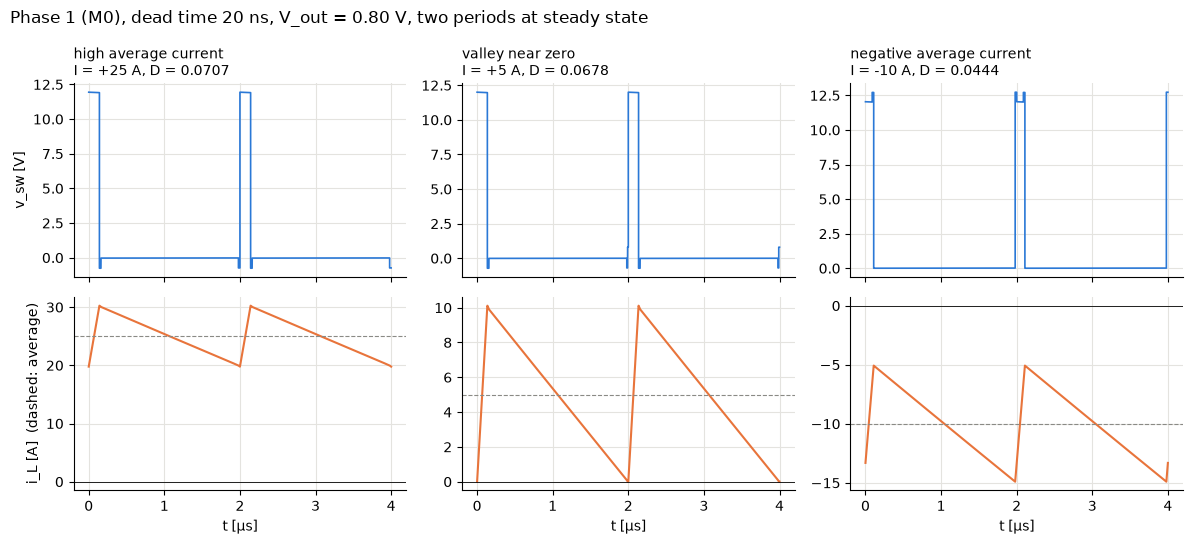

In [7]:
fig, axes = plt.subplots(2, 3, sharex=True, figsize=(12, 5.5))
for col, (name, (i_a, D, w)) in enumerate(waves.items()):
    t_us = w["t"] * 1e6
    ax_v, ax_i = axes[0, col], axes[1, col]
    ax_v.plot(t_us, w["v_sw"], color=BLUE, lw=1.2, drawstyle="steps-pre")
    ax_i.plot(t_us, w["i_l"], color=ORANGE, lw=1.5)
    ax_i.axhline(i_a, color=GREY, lw=0.8, ls="--")
    ax_i.axhline(0.0, color="black", lw=0.6)
    ax_v.set_title(f"{name}\nI = {i_a:+.0f} A, D = {D:.4f}", loc="left", fontsize=10)
    ax_i.set_xlabel("t [µs]")
    for ax in (ax_v, ax_i):
        ax.grid(color="#e4e3df", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_ylabel("v_sw [V]")
axes[1, 0].set_ylabel("i_L [A]  (dashed: average)")
fig.suptitle("Phase 1 (M0), dead time 20 ns, V_out = 0.80 V, two periods at steady state", x=0.01, ha="left")
fig.tight_layout()
plt.show()

The dead times are 20 ns out of 2 µs, invisible at this scale. Zooming on the two edges of the first period shows which device carries the current in each case:

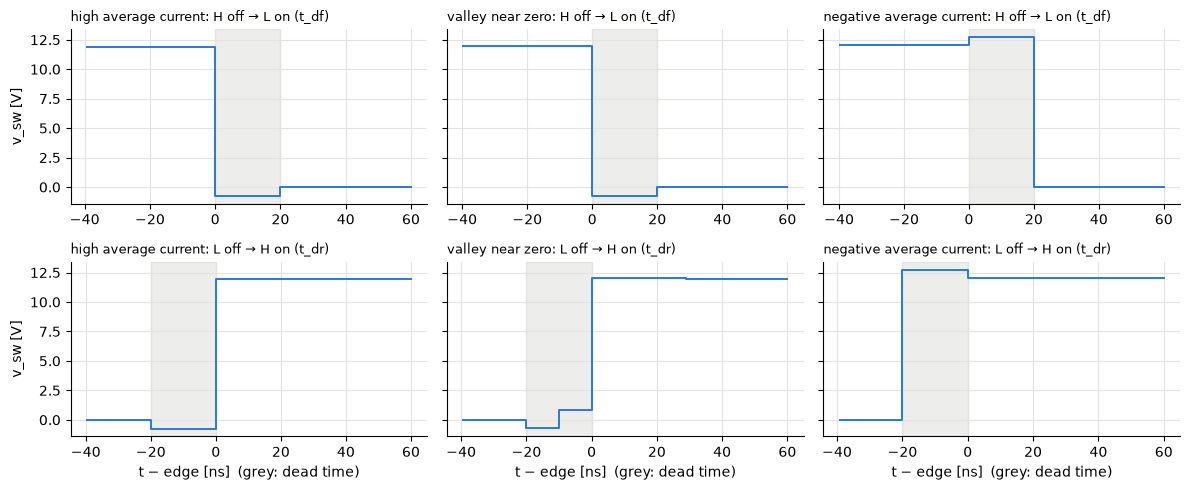

In [8]:
fig, axes = plt.subplots(2, 3, sharey="row", figsize=(12, 5))
for col, (name, (i_a, D, w)) in enumerate(waves.items()):
    t_ns = w["t"] * 1e9
    edges = [("H off → L on (t_df)", D * pp.t_sw_s * 1e9), ("L off → H on (t_dr)", pp.t_sw_s * 1e9)]
    for row, (label, t_edge) in enumerate(edges):
        ax = axes[row, col]
        sel = (t_ns > t_edge - 40) & (t_ns < t_edge + 60)
        ax.plot(t_ns[sel] - t_edge, w["v_sw"][sel], color=BLUE, lw=1.4, drawstyle="steps-pre")
        ax.axvspan(0, 20, color=GREY, alpha=0.15) if row == 0 else ax.axvspan(-20, 0, color=GREY, alpha=0.15)
        ax.set_title(f"{name}: {label}", loc="left", fontsize=9)
        ax.grid(color="#e4e3df", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
    axes[1, col].set_xlabel("t − edge [ns]  (grey: dead time)")
axes[0, 0].set_ylabel("v_sw [V]")
axes[1, 0].set_ylabel("v_sw [V]")
fig.tight_layout()
plt.show()

* **High current**: the current is positive at both edges, so during both dead times the low-side diode conducts and the node sits at $-V_f - R_d i \approx -0.75$ V.
* **Valley near zero**: at the H-off edge (peak current) the low-side diode conducts; at the L-off edge the valley is at zero, so the current dies out inside
  the dead time and the node floats at $v_o$ (DCM, fifth case of eq. 9.2) or, if the valley is slightly negative, jumps to $V_{in}+V_f$ before the high-side turns on.
* **Negative current**: the current flows back into the input through the high-side diode during both dead times: the node is at $V_{in}+V_f \approx 12.7$ V
  *before* the high-side turns on and *after* it turns off. The effective on-time is $D T_{sw} + t_{dr} + t_{df}$: this is the +254 mV of §3.

## 5 · Characteristic "commanded duty → average voltage"

Constant current $I$ (impressed by the load), duty swept, average output voltage at steady state, for three currents and three dead times.
The interesting quantity is the deviation from the dead-time-free eq. 9.3,
$$\Delta V = \langle v_o\rangle - \big(D V_{in} - R_{ph}(D)\, I\big),$$
which is exactly the dead-time distortion seen by the controller.

In [9]:
DEAD_TIMES_S = [5e-9, 20e-9, 40e-9]
CURRENTS_A = [20.0, 5.0, -10.0]
DUTIES = np.linspace(0.03, 0.11, 17)
models_dt = {td: SinglePhaseEventDriven(replace(pp, t_dr_s=td, t_df_s=td)) for td in DEAD_TIMES_S}

char = {(td, i_a): np.array([avg_vout(models_dt[td], D, i_a) for D in DUTIES])
        for td in DEAD_TIMES_S for i_a in CURRENTS_A}

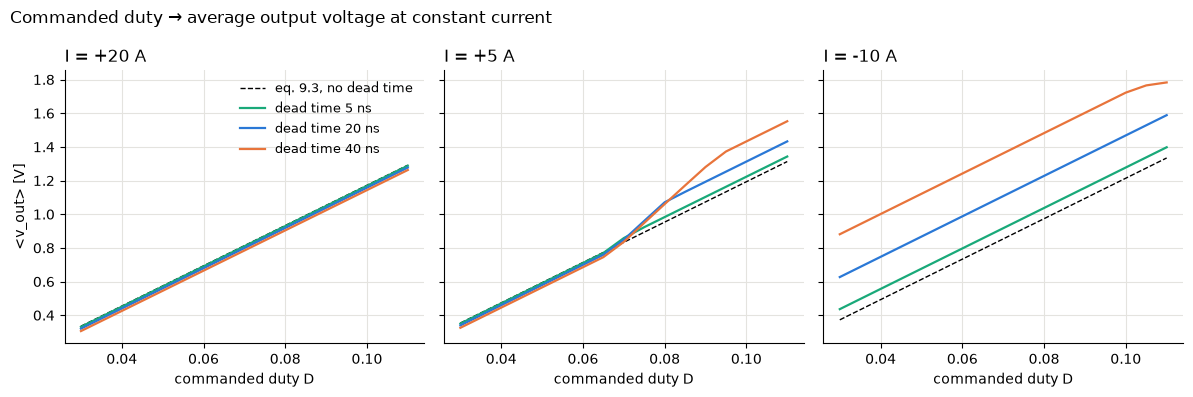

In [10]:
fig, axes = plt.subplots(1, 3, sharey=True, figsize=(12, 4))
for ax, i_a in zip(axes, CURRENTS_A):
    ax.plot(DUTIES, vout_eq_9_3(pp, i_a, DUTIES), color="black", lw=1, ls="--", label="eq. 9.3, no dead time")
    for td, color in zip(DEAD_TIMES_S, [GREEN, BLUE, ORANGE]):
        ax.plot(DUTIES, char[(td, i_a)], color=color, lw=1.6, label=f"dead time {td * 1e9:.0f} ns")
    ax.set_title(f"I = {i_a:+.0f} A", loc="left")
    ax.set_xlabel("commanded duty D")
    ax.grid(color="#e4e3df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("<v_out> [V]")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Commanded duty → average output voltage at constant current", x=0.01, ha="left")
fig.tight_layout()
plt.show()

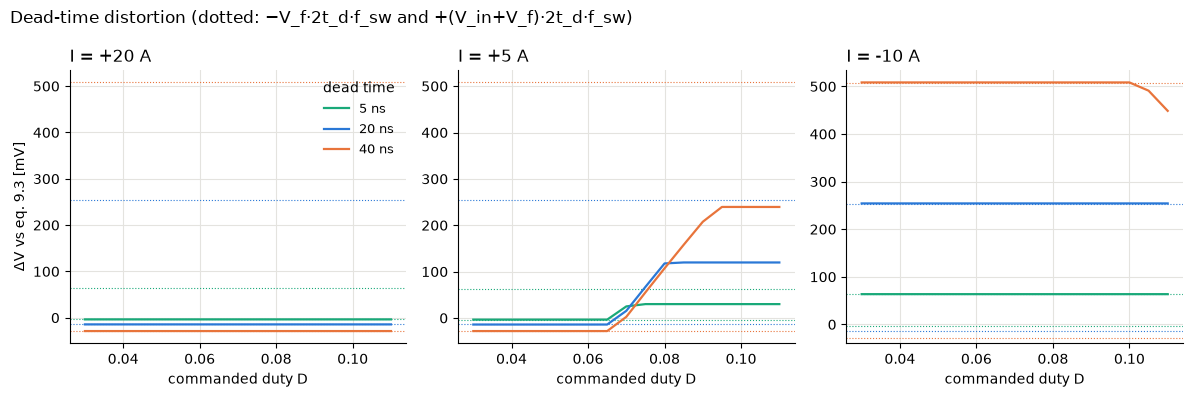

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, i_a in zip(axes, CURRENTS_A):
    for td, color in zip(DEAD_TIMES_S, [GREEN, BLUE, ORANGE]):
        dv = char[(td, i_a)] - vout_eq_9_3(pp, i_a, DUTIES)
        ax.plot(DUTIES, dv * 1e3, color=color, lw=1.6, label=f"{td * 1e9:.0f} ns")
        for level in (-pp.v_f_v * 2 * td * pp.f_sw_hz, (pp.v_in_v + pp.v_f_v) * 2 * td * pp.f_sw_hz):
            ax.axhline(level * 1e3, color=color, lw=0.8, ls=":")
    ax.set_title(f"I = {i_a:+.0f} A", loc="left")
    ax.set_xlabel("commanded duty D")
    ax.grid(color="#e4e3df", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("ΔV vs eq. 9.3 [mV]")
axes[0].legend(title="dead time", frameon=False, fontsize=9)
fig.suptitle("Dead-time distortion (dotted: −V_f·2t_d·f_sw and +(V_in+V_f)·2t_d·f_sw)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

* At **+20 A** the current is positive at both edges for every duty: the distortion is a constant offset of $-V_f\,2t_d f_{sw}$ (−3.5, −14, −28 mV). Annoying but harmless: the integrator removes it.
* At **−10 A** it is the opposite constant offset, $+(V_{in}+V_f)\,2t_d f_{sw}$ (+64, +254, +508 mV): the characteristic is still linear, only shifted.
  With 40 ns and $D > 0.1$ the output rises to ≈1.7 V, the ripple grows and its *peak* crosses zero: the curve starts bending back.
* At **+5 A** the valley sits around zero and moves with the duty (the ripple grows with $D$ through $V_o$): the curve leaves one level and climbs towards the other.
  **Here the gain $\partial \langle v_o\rangle/\partial D$ is not $V_{in}$ any more**: this is the non-linearity of §9.4.

The same effect is clearer sweeping the current at a fixed commanded duty, which is what happens during a load transient or a VID down-ramp:

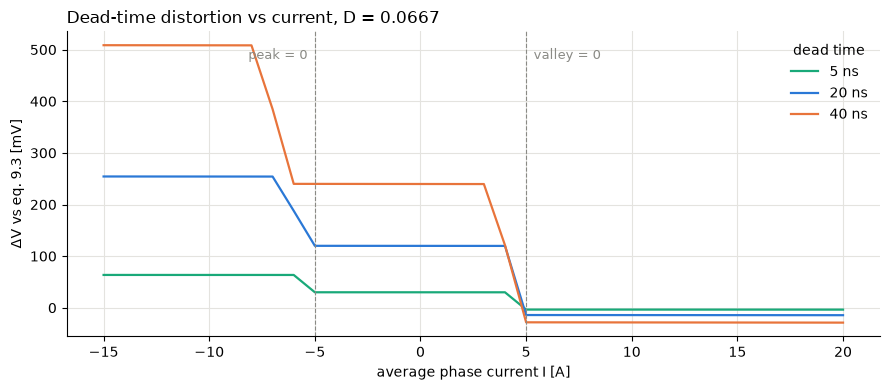

In [12]:
D_FIX = V_OUT_V / pp.v_in_v
CURRENTS_SWEEP_A = np.linspace(-15.0, 20.0, 36)
fig, ax = plt.subplots(figsize=(9, 4))
for td, color in zip(DEAD_TIMES_S, [GREEN, BLUE, ORANGE]):
    dv = [avg_vout(models_dt[td], D_FIX, i_a) - vout_eq_9_3(pp, i_a, D_FIX) for i_a in CURRENTS_SWEEP_A]
    ax.plot(CURRENTS_SWEEP_A, np.array(dv) * 1e3, color=color, lw=1.6, label=f"{td * 1e9:.0f} ns")
half_ripple_a = ripple_eq_9_4(pp, D_FIX, V_OUT_V) / 2
for x in (-half_ripple_a, half_ripple_a):
    ax.axvline(x, color=GREY, lw=0.8, ls="--")
ax.text(half_ripple_a, ax.get_ylim()[1] * 0.9, "  valley = 0", color=GREY, fontsize=9)
ax.text(-half_ripple_a, ax.get_ylim()[1] * 0.9, "peak = 0  ", color=GREY, fontsize=9, ha="right")
ax.set_xlabel("average phase current I [A]")
ax.set_ylabel("ΔV vs eq. 9.3 [mV]")
ax.set_title(f"Dead-time distortion vs current, D = {D_FIX:.4f}", loc="left")
ax.legend(title="dead time", frameon=False)
ax.grid(color="#e4e3df", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Between "peak = 0" and "valley = 0" the distortion moves by $(V_{in}+2V_f)\,2t_d f_{sw}$, ≈ 270 mV at 20 ns, over a few ampere, in two steps.
On the middle plateau only the dead time before the rising edge (at the valley, current negative) lifts the node to $V_{in}+V_f$; the one after the
falling edge (at the peak, current positive) still clamps it to $-V_f$. The lines "peak = 0" and "valley = 0" use the dead-time-free ripple, hence the small shift.
The controller sees a **step** in the plant: a local gain change and an offset that the integrator has to chase every time the valley crosses zero.

## 7 · Results for D1

| Quantity | Formula | Model | Appendix B |
|---|---|---|---|
| Duty at no load / 100 A with load line | eq. 9.3, $V_o = V_{ID} - R_{LL} I_{out}$ | 0.0667 / 0.0669 (§1) | 0.0667 / 0.0669 |
| Duty at 0.8 V, 25 A per phase, no load line | eq. 9.3 | 0.0695, $V_o$ within 2 µV (§2) | — |
| $R_{ph}$ | DCR + D R_on,H + (1−D) R_on,L | 1.33 mΩ | 1.33 mΩ |
| Phase ripple at 25 A | eq. 9.4 | 10.3 A (eq. 9.4 +0.7 %, explained in §2) | 10.0 A |
| Dead time 20 ns, $i>0$ / $i<0$ | Appendix A | −14.5 / +254 mV | −14 / +254 mV |
| Valley at zero, total current, VID 0.6/0.8/1.0 V | $4\cdot\Delta I_L/2$ | §6 Q2 | 15 / 20 / 24 A |
| Duty error 10⁻³ for 1 ms | $V_{in}\Delta D/R_{ph}$, $\tau = L/R_{ph}$ | 9 A, τ = 112 µs | τ = 112 µs |